# Comparing Bivariate Moran's I Across Age and Replicates

**Extends `11b_STARmapPLUS_BivariateMoransI_python.ipynb`**, which runs the ligand-receptor spatial colocalization screen (Gaussian-kernel bivariate Moran's I) on a single tissue section. This notebook generalizes that to the actual experimental design: 2 timepoints (8m "young", 13m "old") x 2 replicate sections each = 4 sections total.

**The one thing that has to change, not just be looped:** the spatial neighbors graph (and everything built on it, local and global Moran's I alike) is inherently a property of one physical piece of tissue. Cell coordinates from replicate 1 have no spatial relationship to cell coordinates from replicate 2 -- they're different slides. So the graph, and `li.mt.bivariate()`, have to be run **separately per section**, never pooled. What *is* shared across sections: the candidate LR pair list, the cell-type vocabulary (`celltype_merged`, assuming it was assigned consistently in the joint clustering step), and the bandwidth choice calibrated in `11b` (400, in the same spatial units).

**What this buys you, and what it doesn't.** With 4 sections (n=2 per age group), this is not enough data for a formal age x score interaction test with real statistical power -- treat this as a reproducibility-first screen instead: does a pair's colocalization show up consistently within an age group's 2 replicates, and does that consistency differ between young and old? That is a much more defensible claim than a p-value from an n=2-per-group comparison would be.

## Imports

In [1]:
import numpy as np
import pandas as pd
import scipy.io as sio
import anndata as ad
import scanpy as sc
import squidpy as sq
import liana as li
import matplotlib.pyplot as plt

/home/vkorob/miniconda3/envs/lianaPlus/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
/home/vkorob/miniconda3/envs/lianaPlus/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)
/home/vkorob/miniconda3/envs/lianaPlus/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
/home/vkorob/miniconda3/envs/lianaPlus/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_mtx from `anndata` is deprecated. Import anndata.io.read_mtx instead.
  warnings.warn(msg, FutureWarning)
/home/vkorob/miniconda3/envs/lianaPlus/lib/python3.10/site-packages/anndata/utils.py:434: 

## Load the combined export and identify the section/age columns

Reuses the same combined export (`expr_norm.mtx`, `coordinates.csv`, `metadata.csv`) that `11b` uses -- since the R export chunk writes out every column of the merged Seurat object's `meta.data`, the `time` and `replicate` columns should already be sitting in `metadata.csv`. There's no single "sample" column: a section is the combination of `time` (`8months`/`13months`) and `replicate` (`replicate_1`/`replicate_2`), so this builds a combined `section_id` column to loop over below, and prints a cross-tab to confirm it lands on exactly 4 sections, 2 per age, before trusting it.

In [2]:
export_dir = "starmap_plus_processed/starmap_hpc_export"

expr = sio.mmread(f"{export_dir}/expr_norm.mtx").tocsr().T  # genes x cells -> cells x genes for AnnData

genes = pd.read_csv(f"{export_dir}/genes.txt", header=None)[0].astype(str).tolist()
cells = pd.read_csv(f"{export_dir}/cells.txt", header=None)[0].astype(str).tolist()

coords = pd.read_csv(f"{export_dir}/coordinates.csv").set_index("cell_id").loc[cells]
meta   = pd.read_csv(f"{export_dir}/metadata.csv").set_index("cell_id").loc[cells]

adata = ad.AnnData(X=expr, obs=meta, var=pd.DataFrame(index=genes))
adata.obsm["spatial"] = coords[["spatial_1", "spatial_2"]].to_numpy()

print("adata.obs columns:", adata.obs.columns.tolist())

# ---- EDIT if these aren't the right column names in your object ----
time_col = "time"
replicate_col = "replicate"

missing = [c for c in (time_col, replicate_col) if c not in adata.obs.columns]
if missing:
    raise RuntimeError(
        f"Missing expected column(s): {missing}. "
        f"Set time_col/replicate_col above to the columns that actually identify age and replicate. "
        f"Columns present: {adata.obs.columns.tolist()}"
    )

age_col = time_col
adata.obs["section_id"] = adata.obs[time_col].astype(str) + "_" + adata.obs[replicate_col].astype(str)
sample_col = "section_id"

print(f"age_col = '{age_col}', values: {sorted(adata.obs[age_col].astype(str).unique().tolist())}")
print(f"sample_col = '{sample_col}' (built from '{time_col}' x '{replicate_col}'), values: {sorted(adata.obs[sample_col].unique().tolist())}")
print(adata.obs.groupby([age_col, sample_col], observed=True).size())

adata.obs columns: ['orig.ident', 'nCount_RNA', 'nFeature_RNA', 'NAME', 'biosample_id', 'donor_id', 'species', 'species__ontology_label', 'sex', 'disease', 'disease__ontology_label', 'organ', 'organ__ontology_label', 'library_preparation_protocol', 'library_preparation_protocol__ontology_label', 'orig_index', 'batch', 'time', 'group', 'replicate', 'label', 'region', 'region_merged', 'top_level_cell_type', 'sub_level_cell_type', 'celltype_merged']
age_col = 'time', values: ['13months', '8months']
sample_col = 'section_id' (built from 'time' x 'replicate'), values: ['13months_replicate_1', '13months_replicate_2', '8months_replicate_1', '8months_replicate_2']
time      section_id          
13months  13months_replicate_1    3901
          13months_replicate_2    4602
8months   8months_replicate_1     3700
          8months_replicate_2     4075
dtype: int64


## Run the spatial graph + bivariate Moran's I separately per section

Loops over every unique value of `sample_col`, building an independent `AnnData` subset, spatial neighbors graph (same bandwidth/kernel calibrated in `11b`), and `bivariate()` call for each -- reusing the exact `bivariate()` arguments from `11b` so per-section results stay comparable. Results are collected into `per_sample` (dict, keyed by sample id); global stats get pulled out into one long-format table right after.

In [3]:
bandwidth = 400  # same choice calibrated in 11b -- revisit per-section if cell density looks very different

lr_pairs = pd.read_csv(f"{export_dir}/lr_pairs.csv")
interactions = list(zip(lr_pairs["ligand_complex"], lr_pairs["receptor_complex"]))

per_sample = {}

for sample_id in sorted(adata.obs[sample_col].unique()):
    print(f"--- {sample_id} ---")
    adata_s = adata[adata.obs[sample_col] == sample_id].copy()

    li.ut.spatial_neighbors(adata_s, bandwidth=bandwidth, kernel="gaussian", set_diag=True)

    bivar_s = li.mt.bivariate(
        adata_s,
        resource_name=None,
        interactions=interactions,
        global_name="morans",
        local_name="morans",
        connectivity_key="spatial_connectivities",
        n_perms=200,
        mask_negatives=False,   # whether to mask LowLow/NegativeNegative interactions
        add_categories=True,    # whether to add local categories to the results
        nz_prop=0,
        seed=1337,
        use_raw=False,
        verbose=False,
    )

    age_val = adata_s.obs[age_col].iloc[0]
    per_sample[sample_id] = {
        "adata": adata_s,
        "bivar_adata": bivar_s,
        "age": age_val,
        "n_cells": adata_s.n_obs,
    }
    print(f"  {adata_s.n_obs} cells, age={age_val}")

--- 13months_replicate_1 ---
  3901 cells, age=13months
--- 13months_replicate_2 ---
  4602 cells, age=13months
--- 8months_replicate_1 ---
  3700 cells, age=8months
--- 8months_replicate_2 ---
  4075 cells, age=8months


## Assemble one long-format table across all 4 sections

One row per (pair, sample) -- everything downstream (reproducibility classification, comparison plots) works off this table rather than re-touching the per-sample AnnDatas directly.

In [4]:
score_col = None
pval_col = None

records = []
for sample_id, res in per_sample.items():
    g = res["bivar_adata"].var.copy()
    if score_col is None:
        score_col = next((c for c in g.columns if "morans" in c.lower() and "pval" not in c.lower()), None)
        pval_col  = next((c for c in g.columns if "pval" in c.lower()), None)
        if score_col is None:
            raise RuntimeError(f"Could not find a Moran's I score column. Columns present: {g.columns.tolist()}")
    g = g.reset_index().rename(columns={"index": "pair_id"})
    g["sample"] = sample_id
    g["age"] = res["age"]
    g["pair_label"] = g["ligand"].astype(str) + " -> " + g["receptor"].astype(str)
    records.append(g)

all_scores = pd.concat(records, ignore_index=True)
n_pairs = all_scores["pair_label"].nunique()
n_samples = all_scores["sample"].nunique()
print(f"{n_pairs} unique pairs x {n_samples} samples = {len(all_scores)} rows")
all_scores.head()

12 unique pairs x 4 samples = 48 rows


,interaction,ligand,receptor,ligand_means,ligand_props,receptor_means,receptor_props,morans,morans_pvals,mean,std,sample,age,pair_label
0,Igfbpl1^Dcc,Igfbpl1,Dcc,0.039144,0.010766,0.102834,0.027942,0.001711,0.43,0.003336,0.172716,13months_replicate_1,13months,Igfbpl1 -> Dcc
1,Ptn^Ptprz1,Ptn,Ptprz1,0.124277,0.031787,0.258645,0.067419,0.004914,0.05,0.010024,0.219367,13months_replicate_1,13months,Ptn -> Ptprz1
2,Fgfr3^Epha4,Fgfr3,Epha4,0.296745,0.074596,0.429501,0.115868,-0.006949,0.00,-0.013981,0.243999,13months_replicate_1,13months,Fgfr3 -> Epha4
3,Efnb2^Grm5,Efnb2,Grm5,0.010269,0.002820,0.053670,0.014612,0.000004,1.00,-0.000378,0.112144,13months_replicate_1,13months,Efnb2 -> Grm5
4,Adam10^Notch2,Adam10,Notch2,0.241387,0.062804,0.406531,0.101000,0.004773,0.02,0.009420,0.201157,13months_replicate_1,13months,Adam10 -> Notch2


## Which pairs colocalize reproducibly, and which age shifts can be trusted?

Two separate questions get answered here:

1. **Within one age group, do both replicates agree on sign?** A pair counts as reproducible for that age group if both of its replicates land on the *same side of zero* -- either both positive (colocalize) or both negative (anti-colocalize/avoid each other). Both-negative is included now, not just both-positive: a consistent negative pattern is just as reproducible as a consistent positive one. No `p < 0.05` requirement -- `min_abs_score` below is a lightweight dead-zone (raise it if a score has to be more than barely off zero to count as a real sign, not just noise straddling the line).
2. **Is there a clean separation between the two age groups' raw scores?** All 2 sections of one age group have to sit strictly above (or strictly below) all 2 sections of the other age group -- `min(old scores) > max(young scores)`, or the mirror image. If even one young section's score lands in between (or past) the old sections' scores, that's `intermixed`: the two groups' actual values overlap, so there's no clean age effect to point to, no matter what the group means look like.

`classification` (`young_only`/`old_only`/`both`/`neither`) still tells you where a pair reproduces (question 1); the new `shift_direction`/`trustworthy_shift` columns answer question 2 -- and they're independent checks, so a pair can be `classification == "both"` and still have `trustworthy_shift == False` if its 4 raw scores interleave across the two ages (e.g. `Efnb2 -> Grm5`).

In [5]:
import re

min_abs_score = 0.0  # ---- EDIT: raise this to treat near-zero scores as "inconsistent" rather than a clean sign ----

def sign_label(x):
    if x > min_abs_score:
        return "positive"
    if x < -min_abs_score:
        return "negative"
    return "zero"

all_scores["sign"] = all_scores[score_col].apply(sign_label)

# how big are the scores actually driving a sign call? -- useful for picking min_abs_score
nonzero_scores = all_scores.loc[all_scores["sign"] != "zero", score_col]
print(f"Score distribution among non-'zero' rows (n={len(nonzero_scores)}): "
      f"min={nonzero_scores.min():.4f}, median={nonzero_scores.median():.4f}, max={nonzero_scores.max():.4f}")

# --- 1) Within one age group: do both replicates land on the SAME side of zero? ---
# Both-positive (colocalize) and both-negative (anti-colocalize) both count as reproducible now --
# only a positive/negative (or either paired with 'zero') split counts as inconsistent.
def group_sign_consistency(signs):
    signs = set(signs)
    if signs == {"positive"}: return "positive"
    if signs == {"negative"}: return "negative"
    return "inconsistent"

sign_per_group = (
    all_scores.groupby(["pair_label", "age"], observed=True)["sign"]
    .apply(group_sign_consistency)
    .unstack(fill_value="inconsistent")
)

def extract_months(age_str):
    """Sort age labels by the number they contain (8 before 13), not lexicographically --
    plain sorted() on strings like '8months'/'13months' would put '13months' first
    ('1' < '8' as characters), silently swapping which group gets called young vs. old."""
    m = re.search(r"\d+", str(age_str))
    return int(m.group()) if m else float("inf")

ages = sorted(all_scores["age"].unique(), key=extract_months)
if len(ages) != 2:
    print(f"Expected exactly 2 age groups, found {ages} -- adjust the young/old classification below to match.")

young_age, old_age = ages[0], ages[1]  # ---- EDIT if this pairing looks wrong for your age labels ----
print(f"Treating '{young_age}' as young_age and '{old_age}' as old_age below.")

sign_per_group = sign_per_group.rename(columns={young_age: "sign_young", old_age: "sign_old"})
sign_per_group["reproducible_young"] = sign_per_group["sign_young"] != "inconsistent"
sign_per_group["reproducible_old"] = sign_per_group["sign_old"] != "inconsistent"

def classify(row):
    y, o = row["reproducible_young"], row["reproducible_old"]
    if y and o: return "both"
    if y: return "young_only"
    if o: return "old_only"
    return "neither"

sign_per_group["classification"] = sign_per_group.apply(classify, axis=1)
print("\nWithin-group reproducibility (both replicates same sign, positive-positive OR negative-negative):")
print(sign_per_group["classification"].value_counts())

# --- 2) Across ages: is there a CLEAN SEPARATION between the two groups' raw scores? ---
# Not "do the replicates individually move the same direction" -- that can pass even when the
# actual numbers overlap (one young section landing higher than an old section, say). This
# instead requires min(old scores) > max(young scores), or the mirror image: every single old
# section has to sit on one side of every single young section, with nothing interleaved. If
# even one section crosses over, the two groups' values overlap and the shift isn't trustworthy,
# no matter what the group means look like (e.g. Efnb2 -> Grm5).
group_range = (
    all_scores.groupby(["pair_label", "age"], observed=True)[score_col]
    .agg(["min", "max"])
    .unstack("age")
)
group_range.columns = [f"{stat}_{age}" for stat, age in group_range.columns]

def classify_shift(row):
    if row[f"min_{old_age}"] > row[f"max_{young_age}"]:
        return "increase_with_age"
    if row[f"max_{old_age}"] < row[f"min_{young_age}"]:
        return "decrease_with_age"
    return "intermixed"

shift_per_pair = group_range.apply(classify_shift, axis=1)
shift_per_pair.name = "shift_direction"

print("\nAge-shift consistency (ALL scores of one age group clearly separated from ALL scores of the other):")
print(shift_per_pair.value_counts())

hits_per_group = sign_per_group.join(shift_per_pair)
hits_per_group["trustworthy_shift"] = hits_per_group["shift_direction"] != "intermixed"
hits_per_group.sort_values(["classification", "shift_direction"])

Score distribution among non-'zero' rows (n=48): min=-0.0120, median=0.0001, max=0.0310
Treating '8months' as young_age and '13months' as old_age below.

Within-group reproducibility (both replicates same sign, positive-positive OR negative-negative):
classification
both          7
old_only      3
young_only    2
Name: count, dtype: int64

Age-shift consistency (ALL scores of one age group clearly separated from ALL scores of the other):
shift_direction
intermixed           6
increase_with_age    5
decrease_with_age    1
Name: count, dtype: int64


,sign_old,sign_young,reproducible_young,reproducible_old,classification,shift_direction,trustworthy_shift
pair_label,,,,,,,
Spon1 -> App,positive,positive,True,True,both,decrease_with_age,True
Adam10 -> Notch2,positive,negative,True,True,both,increase_with_age,True
Apoe -> Sorl1,positive,negative,True,True,both,increase_with_age,True
Pdgfa -> Pdgfra,positive,negative,True,True,both,increase_with_age,True
Bsg -> Slc16a7,negative,negative,True,True,both,intermixed,False
Efnb2 -> Grm5,positive,positive,True,True,both,intermixed,False
Fgfr3 -> Epha4,negative,negative,True,True,both,intermixed,False
Igfbpl1 -> Dcc,positive,inconsistent,False,True,old_only,increase_with_age,True
Ptn -> Ptprz1,positive,inconsistent,False,True,old_only,increase_with_age,True


## Compare per-pair scores across all 4 sections

For every pair that was a reproducible hit in at least one age group (`classification != "neither"`), plot its global Moran's I score in each of the 4 sections -- jittered vertically within a pair's row, colored by age -- so a real age shift (both old points clearly separated from both young points) is visually distinguishable from noisy overlap between the two groups.

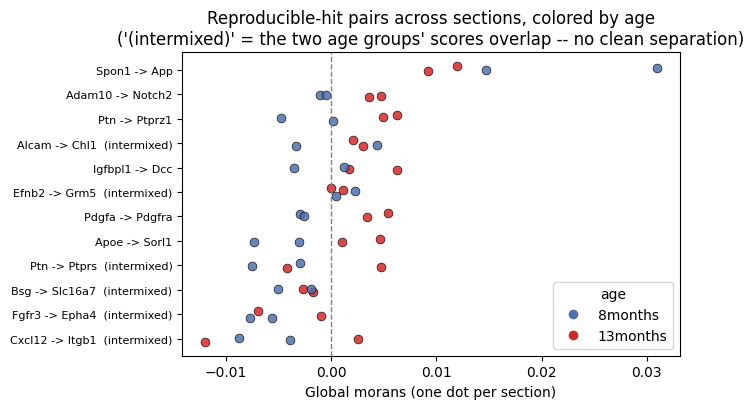

In [6]:
plot_pairs = hits_per_group[hits_per_group["classification"] != "neither"].index.tolist()
plot_data = all_scores[all_scores["pair_label"].isin(plot_pairs)].copy()

rng = np.random.default_rng(0)

pair_order = (
    plot_data.groupby("pair_label", observed=True)[score_col].mean().sort_values(ascending=False).index.tolist()
)
pair_y = {p: i for i, p in enumerate(pair_order)}
colors = {young_age: "#4c72b0", old_age: "#d62728"}

fig, ax = plt.subplots(figsize=(7, max(4, 0.35 * len(pair_order))))

for _, row in plot_data.iterrows():
    y = pair_y[row["pair_label"]] + rng.uniform(-0.15, 0.15)
    ax.scatter(row[score_col], y, color=colors.get(row["age"], "#999999"), s=40, alpha=0.85,
               edgecolors="black", linewidths=0.5)

ax.set_yticks(range(len(pair_order)))
# flag pairs whose two age groups' raw scores overlap -- those dots may look fine at a glance
# (both groups roughly separated on average) but a section-by-section look shows interleaving
ytick_labels = [
    f"{p}  (intermixed)" if not hits_per_group.loc[p, "trustworthy_shift"] else p
    for p in pair_order
]
ax.set_yticklabels(ytick_labels, fontsize=8)
ax.invert_yaxis()
ax.axvline(0, color="grey", linestyle="--", linewidth=1)
ax.set_xlabel(f"Global {score_col} (one dot per section)")
ax.set_title("Reproducible-hit pairs across sections, colored by age\n('(intermixed)' = the two age groups' scores overlap -- no clean separation)")
handles = [plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=c, markersize=8, label=a)
           for a, c in colors.items()]
ax.legend(handles=handles, title="age", loc="lower right")
plt.tight_layout()
plt.show()

## Does a pair switch colocalization state between ages?

The dot plot above shows every reproducible-hit pair's 4 individual section scores; this asks the same question the Visium pipeline's age-interaction model asked (`03`'s `slope_young` vs `slope_old` quadrant scatter, "off-diagonal = age-dependent change") but for the global Moran's I score itself rather than a coloc-tracking slope: for each pair, plot its mean score in young against its mean score in old. A pair sitting on the diagonal colocalizes the same way at both ages; a pair sitting off the diagonal -- especially one that sits near zero on one axis and clearly positive on the other -- is a candidate for "doesn't colocalize at one timepoint, does at the other," the spatial-colocalization analogue of an LR pair whose expression-vs-colocalization coupling showed up only in young (or only in old) in the Visium analysis.

**Trust the shift, not just the mean.** A pair's mean-based position on this plot can look convincingly off-diagonal even when its actual per-section scores overlap between the two age groups (`shift_direction == "intermixed"`, see the cell above) -- the group means can differ while individual sections still interleave. Those pairs are drawn as hollow `x` markers here instead of filled dots -- they're shown so nothing is hidden, but shouldn't be read as a real age-dependent switch.

`switch_candidates` below ranks the `young_only`/`old_only` pairs by the size of that shift (`|mean_old - mean_young|`), with `shift_direction`/`trustworthy_shift` included so the intermixed ones are visible rather than silently mixed in with the real ones.

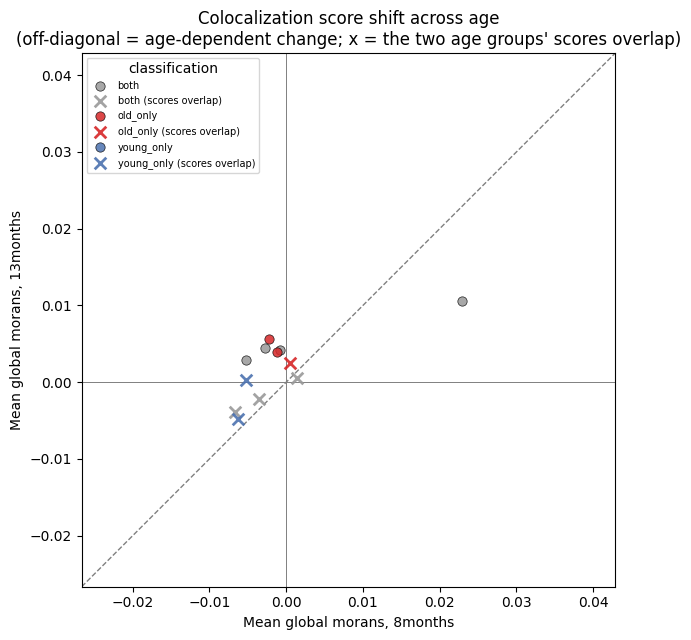

3/5 switch candidate(s) have overlapping raw scores between the two age groups (trustworthy_shift == False) -- treat those as noisy, not a real age-dependent switch.


,pair_label,classification,mean_young,mean_old,delta,shift_direction,trustworthy_shift
10,Ptn -> Ptprz1,old_only,-0.002274,0.005613,0.007887,increase_with_age,True
9,Ptn -> Ptprs,young_only,-0.005220,0.000250,0.005469,intermixed,False
7,Igfbpl1 -> Dcc,old_only,-0.001136,0.003991,0.005127,increase_with_age,True
1,Alcam -> Chl1,old_only,0.000504,0.002554,0.002051,intermixed,False
4,Cxcl12 -> Itgb1,young_only,-0.006317,-0.004730,0.001587,intermixed,False


In [7]:
pair_means = (
    all_scores.groupby(["pair_label", "age"], observed=True)[score_col]
    .mean()
    .unstack("age")
    .rename(columns={young_age: "mean_young", old_age: "mean_old"})
)

shift_df = pair_means.join(hits_per_group[["classification", "shift_direction", "trustworthy_shift"]]).reset_index()
shift_df["delta"] = shift_df["mean_old"] - shift_df["mean_young"]

# same scope as the dot plot above -- pairs that never reproduced as a hit in either
# age group are left out, so the diagonal plot isn't cluttered with pure noise
plot_shift = shift_df[shift_df["classification"] != "neither"].copy()

class_colors = {"both": "#999999", "young_only": "#4c72b0", "old_only": "#d62728"}

fig, ax = plt.subplots(figsize=(6.5, 6.5))

for cls, sub in plot_shift.groupby("classification", observed=True):
    trust_sub = sub[sub["trustworthy_shift"]]
    untrust_sub = sub[~sub["trustworthy_shift"]]
    ax.scatter(trust_sub["mean_young"], trust_sub["mean_old"], color=class_colors.get(cls, "black"),
               s=45, alpha=0.85, edgecolors="black", linewidths=0.5, label=cls, zorder=3)
    if len(untrust_sub):
        ax.scatter(untrust_sub["mean_young"], untrust_sub["mean_old"], color=class_colors.get(cls, "black"),
                   marker="x", s=70, linewidths=2, alpha=0.9, zorder=4,
                   label=f"{cls} (scores overlap)")

lo = min(plot_shift["mean_young"].min(), plot_shift["mean_old"].min(), 0) - 0.02
hi = max(plot_shift["mean_young"].max(), plot_shift["mean_old"].max(), 0) + 0.02

ax.plot([lo, hi], [lo, hi], color="grey", linestyle="--", linewidth=1, zorder=1)
ax.axhline(0, color="grey", linewidth=0.7, zorder=0)
ax.axvline(0, color="grey", linewidth=0.7, zorder=0)
ax.set_xlim(lo, hi)
ax.set_ylim(lo, hi)
ax.set_aspect("equal")
ax.set_xlabel(f"Mean global {score_col}, {young_age}")
ax.set_ylabel(f"Mean global {score_col}, {old_age}")
ax.set_title("Colocalization score shift across age\n(off-diagonal = age-dependent change; x = the two age groups' scores overlap)")
ax.legend(title="classification", loc="best", fontsize=7)
plt.tight_layout()
plt.show()

switch_candidates = shift_df[shift_df["classification"].isin(["young_only", "old_only"])].copy()
switch_candidates = switch_candidates.reindex(
    switch_candidates["delta"].abs().sort_values(ascending=False).index
)

n_untrustworthy = (~switch_candidates["trustworthy_shift"]).sum()
if n_untrustworthy:
    print(f"{n_untrustworthy}/{len(switch_candidates)} switch candidate(s) have overlapping raw scores between the "
          f"two age groups (trustworthy_shift == False) -- treat those as noisy, not a real age-dependent switch.")

switch_candidates[["pair_label", "classification", "mean_young", "mean_old", "delta", "shift_direction", "trustworthy_shift"]]

## Normalized expression per cell type, by age and replicate -- non-intermixed pairs

For every pair whose age shift survived the raw-score separation check above (`trustworthy_shift == True`, i.e. `shift_direction != "intermixed"` -- so this excludes any pair where the two age groups' section-level scores actually overlap), this plots each gene's own log-normalized expression per cell type, broken out by individual section (age x replicate) rather than pooled across all 4 -- so a spatial-score shift can be checked against whether the underlying expression level itself moved with age, and whether both replicates of an age group agree.

Reuses the `complex_expression()` pattern from `11b` (mean across a multi-subunit complex's genes, if any -- none of these pairs need it, but kept defensive), applied here to the full combined `adata` built in the cell above (not the per-section subsets in `per_sample`), since expression itself doesn't depend on the per-section spatial graph the way the Moran's I score does.

6 non-intermixed pair(s): ['Adam10 -> Notch2', 'Apoe -> Sorl1', 'Igfbpl1 -> Dcc', 'Pdgfa -> Pdgfra', 'Ptn -> Ptprz1', 'Spon1 -> App']


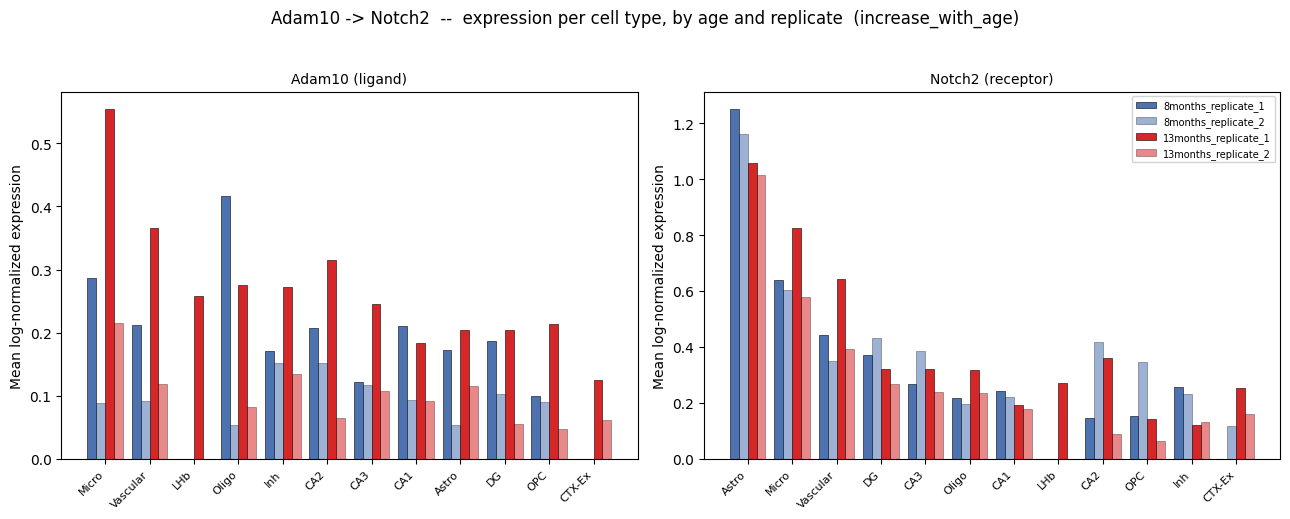

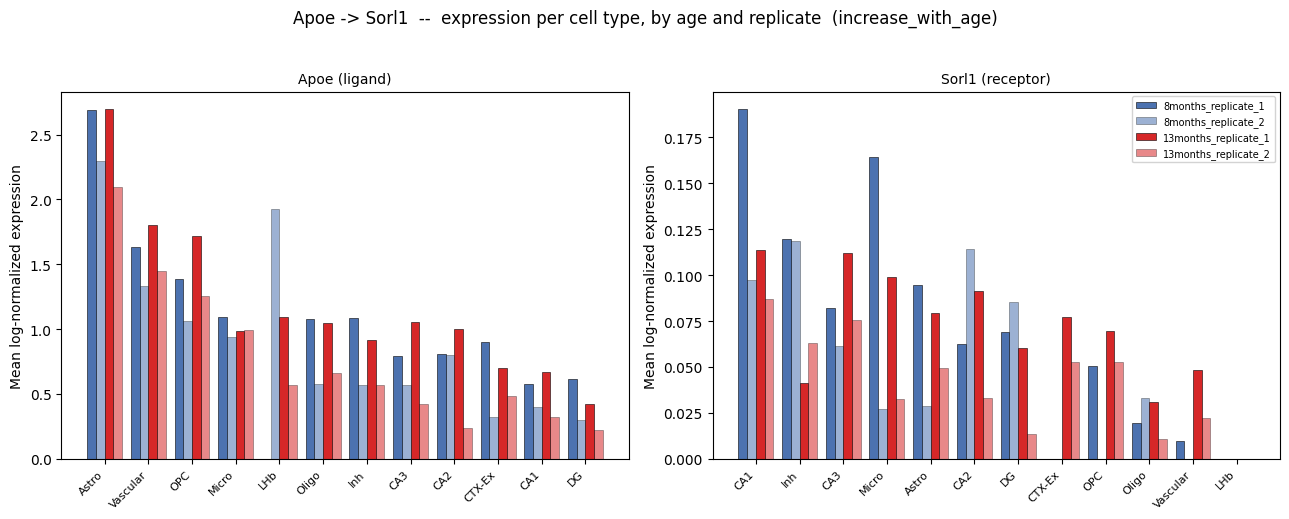

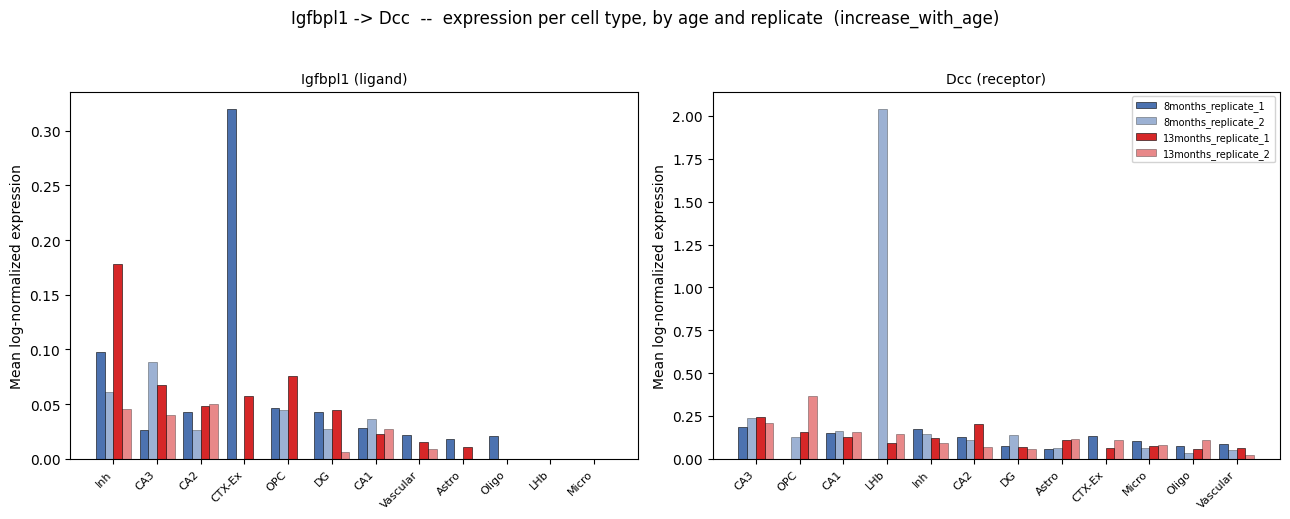

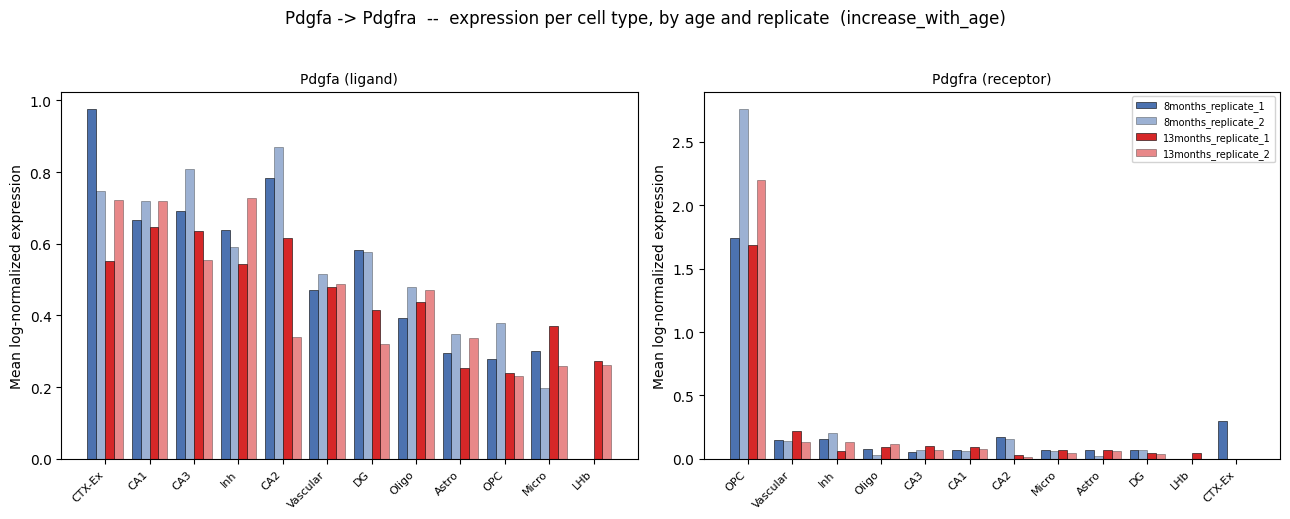

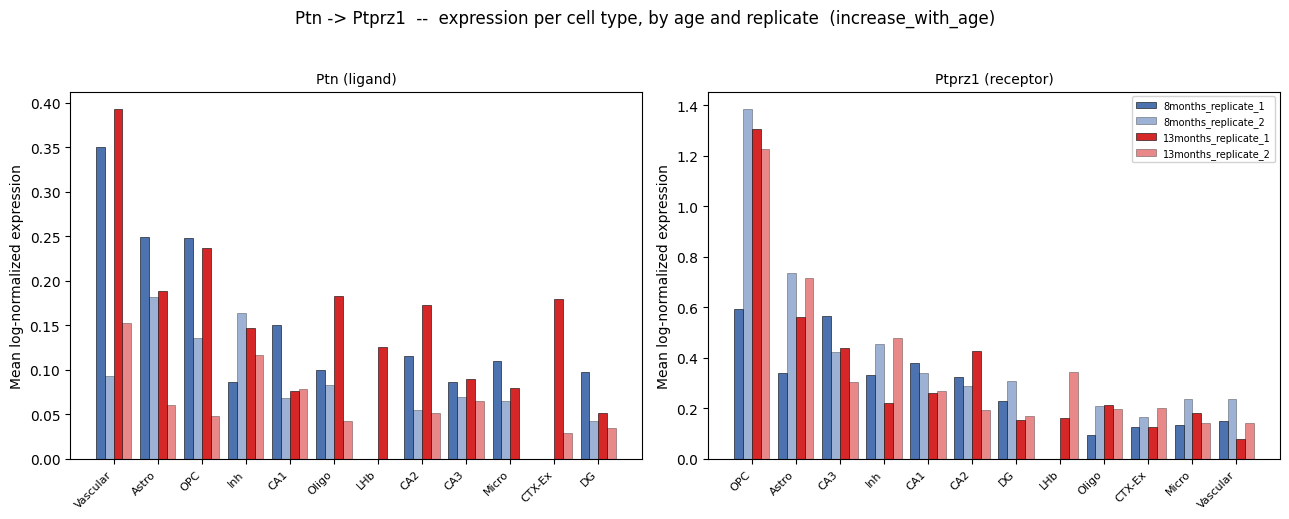

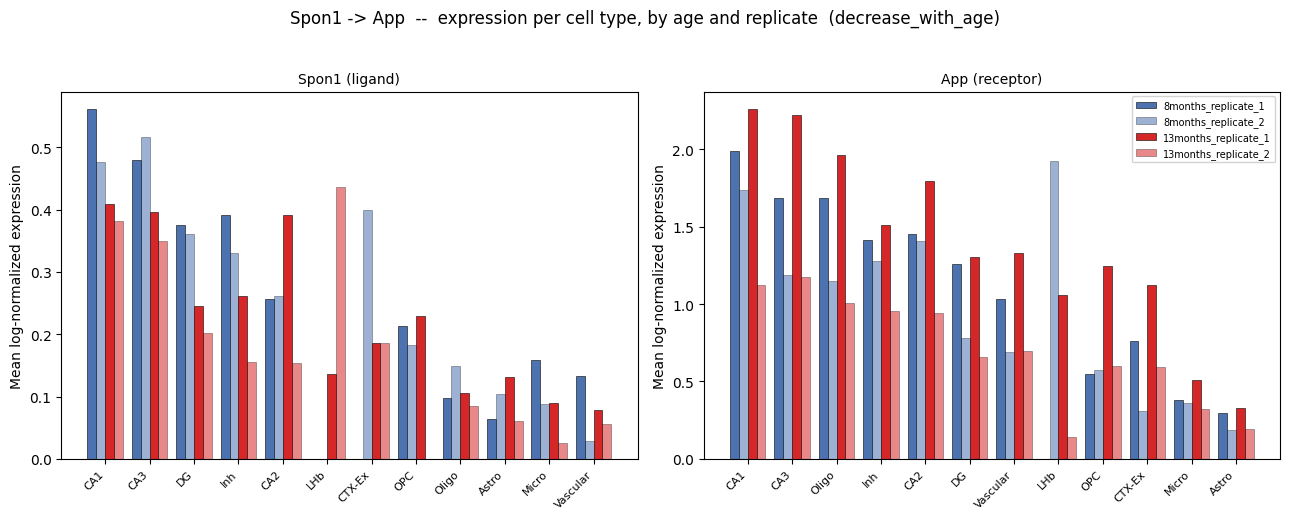

In [8]:
def complex_expression(adata_obj, complex_str):
    """Mean log-normalized expression across a complex's subunit genes (genes joined by '_', if
    any) -- same pattern as 11b's complex_expression(), generalized to take an AnnData explicitly
    since this notebook has both the full combined `adata` and per-section subsets in `per_sample`."""
    genes_present = [g for g in str(complex_str).split("_") if g in adata_obj.var_names]
    if len(genes_present) == 0:
        return None
    vals = adata_obj[:, genes_present].X
    vals = np.asarray(vals.todense()) if hasattr(vals, "todense") else np.asarray(vals)
    return vals.mean(axis=1)

celltype_col = "celltype_merged" if "celltype_merged" in adata.obs.columns else "top_level_cell_type"

non_intermixed_pairs = hits_per_group[hits_per_group["trustworthy_shift"]].index.tolist()
print(f"{len(non_intermixed_pairs)} non-intermixed pair(s): {non_intermixed_pairs}")

pair_lookup = all_scores.drop_duplicates("pair_label").set_index("pair_label")[["ligand", "receptor"]]

# Consistent section order: young (both replicates), then old (both replicates) -- not the
# lexicographic order adata.obs would give, which puts '13months' before '8months'.
replicate_vals = sorted(adata.obs[replicate_col].astype(str).unique())
section_order = [f"{age}_{rep}" for age in (young_age, old_age) for rep in replicate_vals]
section_order = [s for s in section_order if s in set(adata.obs[sample_col])]
age_for_section = adata.obs.drop_duplicates(sample_col).set_index(sample_col)[age_col].to_dict()

for pair_label in non_intermixed_pairs:
    ligand_gene = pair_lookup.loc[pair_label, "ligand"]
    receptor_gene = pair_lookup.loc[pair_label, "receptor"]

    ligand_expr = complex_expression(adata, ligand_gene)
    receptor_expr = complex_expression(adata, receptor_gene)
    if ligand_expr is None or receptor_expr is None:
        print(f"Skipping {pair_label}: '{ligand_gene}'/'{receptor_gene}' not found in adata.var_names")
        continue

    df = pd.DataFrame({
        celltype_col: adata.obs[celltype_col].values,
        sample_col: adata.obs[sample_col].values,
        "ligand": ligand_expr,
        "receptor": receptor_expr,
    })

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for ax, gene_role, gene_name in [(axes[0], "ligand", ligand_gene), (axes[1], "receptor", receptor_gene)]:
        by_type_overall = df.groupby(celltype_col, observed=True)[gene_role].mean().sort_values(ascending=False)
        celltypes_order = by_type_overall.index.tolist()

        by_type_section = (
            df.groupby([celltype_col, sample_col], observed=True)[gene_role]
            .mean()
            .unstack(sample_col)
            .reindex(index=celltypes_order, columns=section_order)
        )

        x = np.arange(len(celltypes_order))
        n_sections = len(section_order)
        bar_width = 0.8 / n_sections

        for i, section in enumerate(section_order):
            offset = (i - (n_sections - 1) / 2) * bar_width
            age_val = age_for_section[section]
            is_rep2 = not section.endswith(replicate_vals[0])  # 2nd+ replicate drawn lighter
            ax.bar(
                x + offset, by_type_section[section].to_numpy(), width=bar_width,
                color=colors.get(age_val, "#999999"), alpha=0.55 if is_rep2 else 1.0,
                edgecolor="black", linewidth=0.4, label=section,
            )

        ax.set_xticks(x)
        ax.set_xticklabels(celltypes_order, rotation=45, ha="right", fontsize=8)
        ax.set_ylabel("Mean log-normalized expression")
        ax.set_title(f"{gene_name} ({gene_role})", fontsize=10)

    axes[1].legend(fontsize=7, loc="upper right", framealpha=0.85)
    plt.suptitle(f"{pair_label}  --  expression per cell type, by age and replicate  "
                 f"({hits_per_group.loc[pair_label, 'shift_direction']})", y=1.03)
    plt.tight_layout()
    plt.show()

## Save results for downstream use

In [9]:
all_scores.to_csv(f"{export_dir}/bivariate_morans_by_sample.csv", index=False)
hits_per_group.to_csv(f"{export_dir}/bivariate_morans_age_classification.csv")
shift_df.to_csv(f"{export_dir}/bivariate_morans_age_shift.csv", index=False)
print(f"Saved {export_dir}/bivariate_morans_by_sample.csv, "
      f"{export_dir}/bivariate_morans_age_classification.csv, and "
      f"{export_dir}/bivariate_morans_age_shift.csv")

Saved starmap_plus_processed/starmap_hpc_export/bivariate_morans_by_sample.csv, starmap_plus_processed/starmap_hpc_export/bivariate_morans_age_classification.csv, and starmap_plus_processed/starmap_hpc_export/bivariate_morans_age_shift.csv


## Notes / next steps

This screens at the global-Moran's-I level only -- deliberately, since that is the level at which a 4-section comparison is actually defensible with n=2 per group. To go deeper on a specific pair that comes out `old_only` or `young_only` (re-running `11b`'s local-score, cell-type-enrichment, and "understanding the local score" sections, but per section instead of pooled), index into `per_sample[<sample_id>]["adata"]` / `["bivar_adata"]` directly -- they hold exactly what `11b`'s `adata` / `bivar_adata` hold, just for one section instead of the whole tissue.

A natural follow-up once a handful of `old_only` (or `young_only`) candidates are in hand: does the cell type that dominates the colocalization (per `11b`'s enrichment analysis) also shift with age, or is it the same cell type doing it more or less strongly?